# Groups of subjects: a hierarchy of templates

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/13_group_hierarchy.ipynb)
[![PyPI version](https://img.shields.io/pypi/v/htfa.svg)](https://pypi.org/project/htfa/)

HTFA ties every subject's factors to one global template. With `groups`, `HTFA.fit` fits one template per group of subjects under the global template instead: each subject's prior is centred on its group's template, each group's prior on the global template, and factor `k` is the same factor in every template. Groups can be nested further, with each subject belonging to one group at each level. A hypothetical multisite study with participant groups within each site is one example of that structure; group labels need not refer to sites or diagnoses. `htfa.group_permutation_test` then asks, factor by factor, whether the groups differ in where a factor is (its center), how large it is (its width) or how it is connected to the other factors, by shuffling the group labels and refitting.

**Data used in each section.**

- Sections 1 to 3: synthetic data from `htfa.make_group_data`, with known group differences (section 1), with none (section 2, a control for false positives) and with two nested levels (section 3).
- Sections 4 to 7: an illustrative age-group comparison using ten children and ten adults from nilearn's `development_fmri` dataset. All participants watch Pixar's short animated film *Partly Cloudy*, with 168 brain volumes acquired 2 seconds apart (TR). The model has one template for each selected age group under a shared template for these 20 participants.

The first run downloads the twenty runs of the dataset (about 25 MB each) and, by default, the saved fit and permutation null of section 4 (see there); later runs reuse the downloaded files.

In [2]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q htfa

In [3]:
import json
import os
import time
import warnings

import numpy as np
from sklearn.exceptions import ConvergenceWarning

import htfa
from htfa.groups import GroupTest, group_tree
from htfa.synthetic import match_factors

plt = htfa.require("matplotlib.pyplot")
warnings.filterwarnings("ignore", category=ConvergenceWarning)
T_START = time.perf_counter()

## 1. Synthetic groups with known differences

`htfa.make_group_data` draws a global template, moves it per group (`center_shift`, `width_scale`) and draws each group's subjects around their group's template, as `make_htfa_data` does around the global one. Here two groups of 5 subjects share 5 factors on a 16 x 16 grid; in group 1, factor 0 moves 3 grid units along the first axis (toward the middle of the grid) and factor 1 is twice as wide. Subjects scatter around their group template by 0.5 grid units (`center_jitter`).

In [4]:
K = 5
SIZES = (5, 5)


def group_data(shift, scale, seed):
    # the global centers do not depend on the shifts: move factor 0 toward the
    # middle of the grid so that it stays inside
    g = htfa.make_group_data(SIZES, (16, 16), 2, K=K, random_state=seed)[3]
    toward = -np.sign(g["global_centers"][0, 0] - 7.5)
    center_shift = np.zeros((2, K, 2))
    center_shift[1, 0, 0] = toward * shift
    width_scale = np.ones((2, K))
    width_scale[1, 1] = scale
    return htfa.make_group_data(
        SIZES,
        grid_shape=(16, 16),
        n_samples=40,
        K=K,
        center_shift=center_shift,
        width_scale=width_scale,
        center_jitter=0.5,
        random_state=seed,
    )


Xs, Rs, groups, truth = group_data(shift=3.0, scale=2.0, seed=0)
print("subjects:", len(Xs), " groups:", groups)
print(
    "true group 1 - group 0, factor 0 center:",
    truth["group_centers"][1, 0] - truth["group_centers"][0, 0],
)
print(
    "true width ratio, factor 1:",
    truth["group_widths"][1, 1] / truth["group_widths"][0, 1],
)

subjects: 10  groups: [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
true group 1 - group 0, factor 0 center: [-3.  0.]
true width ratio, factor 1: 2.0


Groups need `template_update='fixed'` or `'empirical'` (BrainIAK's update, the default, takes its prior from its own previous estimate rather than from a parent template, and raises an error with groups). The fit returns the global template (`global_centers_`), one template per group (`group_centers_`, `group_widths_`, keyed by `group_keys_`) and their posterior covariances (`group_centers_cov_`).

In [5]:
t0 = time.perf_counter()
model = htfa.HTFA(K=K, template_update="fixed", standardize=False, random_state=0)
model.fit(Xs, Rs, groups=groups)
print(
    f"fit: {time.perf_counter() - t0:.1f} s, {model.n_iter_} global iterations "
    f"({model.converged_reason_})"
)
print("group keys:", model.group_keys_)
print(
    "group_centers_:",
    model.group_centers_.shape,
    " group_centers_cov_:",
    model.group_centers_cov_.shape,
)

perm = match_factors(truth["global_centers"], model.global_centers_)  # truth order
est = model.group_centers_[:, perm]
sd = np.sqrt(model.group_centers_cov_[:, perm, 0, 0])
print("\nfactor | estimated group 1 - group 0 (axis 0, axis 1) | true | posterior SD")
for k in range(K):
    d = est[1, k] - est[0, k]
    t = truth["group_centers"][1, k] - truth["group_centers"][0, k]
    print(
        f"  {k}    | {d[0]:6.2f} {d[1]:6.2f}                          "
        f"| {t[0]:4.1f} {t[1]:4.1f} | {sd[0, k]:.2f}"
    )
ratio = model.group_widths_[1, perm] / model.group_widths_[0, perm]
print("\nwidth ratio group 1 / group 0:", np.round(ratio, 2))

fit: 0.6 s, 2 global iterations (threshold)
group keys: [0, 1]
group_centers_: (2, 5, 2)  group_centers_cov_: (2, 5, 2, 2)

factor | estimated group 1 - group 0 (axis 0, axis 1) | true | posterior SD
  0    |  -3.03  -0.11                          | -3.0  0.0 | 1.16
  1    |  -0.14   0.13                          |  0.0  0.0 | 1.16
  2    |  -0.10  -0.35                          |  0.0  0.0 | 1.16
  3    |  -0.03  -0.23                          |  0.0  0.0 | 1.16
  4    |  -0.02   0.22                          |  0.0  0.0 | 1.16

width ratio group 1 / group 0: [1.05 1.78 0.99 0.99 0.99]


Factor 0's estimated move is close to the true 3 grid units and the other factors barely move. Each group template is pulled toward the global template as if by one extra subject placed there: for two groups of 5 the estimated difference is 5/6 of the difference between the groups' subject means (which here is itself not exactly 3, since only five subjects per group scatter around each template). The width ratio of factor 1 is shrunk the same way.

The figure shows the mean image of subject 0 with the true group templates (open markers) and the estimated ones (filled), using `HTFAResults.plot_nodes(group=...)`, which draws a group template in black and its subjects' centers in color.

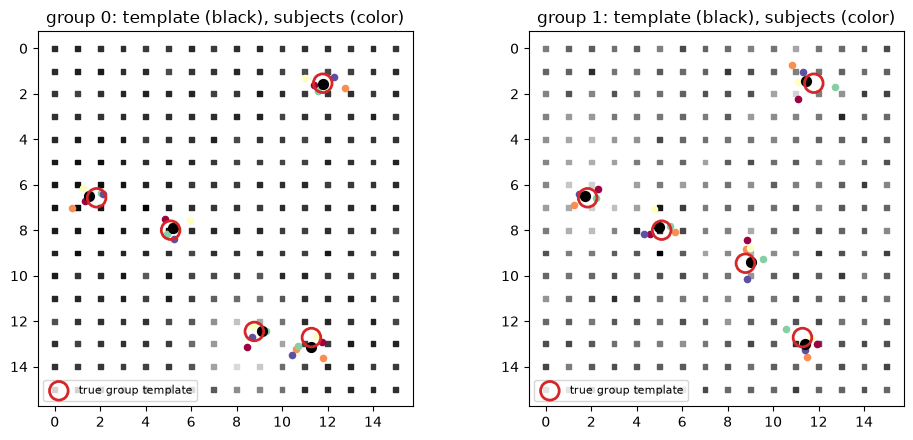

In [6]:
res = htfa.HTFAResults(model, htfa.load(Xs, coords=Rs))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, g in zip(axes, model.group_keys_, strict=True):
    res.plot_nodes(group=g, ax=ax, snap=False)
    tc = truth["group_centers"][g]
    ax.scatter(
        tc[:, 1],
        tc[:, 0],
        s=180,
        facecolors="none",
        edgecolors="tab:red",
        linewidths=2,
        zorder=5,
        label="true group template",
    )
    ax.set_title(f"group {g}: template (black), subjects (color)")
    ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

### The permutation test

`htfa.group_permutation_test(model, X, coords, n_permutations, random_state)` refits the model with the group labels shuffled among the subjects (`n_permutations` times) and also refits with the observed labels. It reuses the label-independent, unpenalized first-stage fits and compares three statistics per factor with their permutation distributions:

- `center`: how far the group templates' centers are from their (subject-weighted) mean, in coordinate units; for two groups it is proportional to the distance between them;
- `width`: the same for the log widths;
- `connectivity`: the same for the factor's row of the groups' mean (Fisher z) static connectivity.

`test.pvalues(stat)` gives `(1 + number of permutations at least as large) / (1 + n_permutations)` per factor; `test.pvalues(stat, fwe=True)` compares each factor with the largest statistic over all factors of each permutation, which provides a max-statistic correction across the K factors under the permutation test's exchangeability assumptions. With 39 permutations the smallest possible p-value is 1/40 = 0.025.

Every refit's global factors are matched to the same reference: the first subject's unpenalized stage-0 centers. The reference is fixed independently of group labels. A single common permutation then displays the observed statistics and all null samples in the supplied model's factor order. `test.reference_centers` stores the reference and `test.reference_indices` identifies the reference factor for each displayed column.

An uncorrected per-factor p-value addresses a prespecified reference factor. Selecting a factor because its observed group difference is large requires correction across factors, such as `fwe=True`. The max-statistic correction covers factors within one statistic, not simultaneous exploration of center, width, and connectivity effects. Caller-supplied starting fits must also be independent of the tested labels.

Use a predetermined subject order; do not select the reference subject using the tested labels or observed effects.

In [7]:
t0 = time.perf_counter()
test = htfa.group_permutation_test(model, Xs, Rs, n_permutations=39, random_state=0)
print(f"39 refits: {time.perf_counter() - t0:.1f} s")
for stat in ("center", "width", "connectivity"):
    print(f"{stat:>12} p (truth order):      ", np.round(test.pvalues(stat)[perm], 3))
    print(
        f"{stat:>12} p, family-wise:       ",
        np.round(test.pvalues(stat, fwe=True)[perm], 3),
    )

39 refits: 4.7 s
      center p (truth order):       [0.025 0.825 0.475 0.85  0.5  ]
      center p, family-wise:        [0.025 1.    0.975 1.    1.   ]
       width p (truth order):       [0.075 0.025 0.575 0.825 0.35 ]
       width p, family-wise:        [1.    0.025 1.    1.    1.   ]
connectivity p (truth order):       [0.975 0.475 0.875 0.85  0.65 ]
connectivity p, family-wise:        [1.    0.925 1.    1.    0.975]


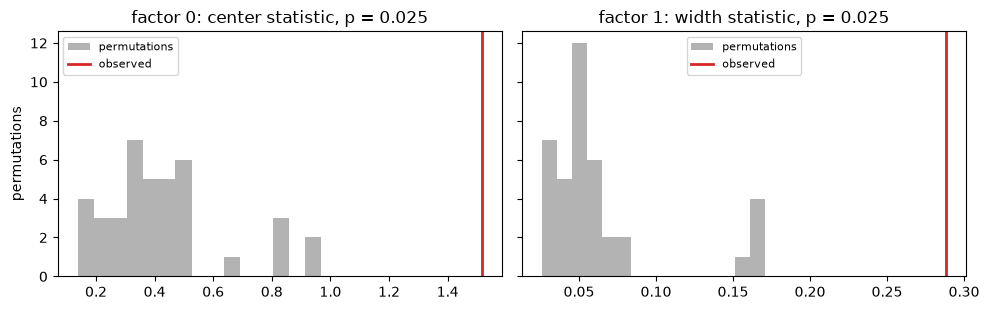

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, stat, k in zip(axes, ("center", "width"), (0, 1), strict=True):
    f = perm[k]  # model index of true factor k
    ax.hist(
        getattr(test, f"{stat}_null")[:, f], bins=15, color="0.7", label="permutations"
    )
    ax.axvline(getattr(test, stat)[f], color="tab:red", lw=2, label="observed")
    ax.set_title(f"factor {k}: {stat} statistic, p = {test.pvalues(stat)[f]:.3f}")
    ax.legend(fontsize=8)
axes[0].set_ylabel("permutations")
plt.tight_layout()
plt.show()

## 2. A control: no true difference

This control uses the same generator with no group shift or width change. Apparent template differences arise from random subject variation and estimation, rather than an imposed group effect. The printed p-values illustrate one null dataset; they are not a calibration study. One simulated dataset cannot establish the false-positive rate. Assessing calibration requires repeating the complete analysis over independent datasets generated under a null hypothesis; the Validation guide discusses such repeated checks, and `scripts/validation_groups.py fpr` provides a simulation workflow.

In [9]:
Xs0, Rs0, groups0, truth0 = group_data(shift=0.0, scale=1.0, seed=1)
model0 = htfa.HTFA(K=K, template_update="fixed", standardize=False, random_state=0)
model0.fit(Xs0, Rs0, groups=groups0)
test0 = htfa.group_permutation_test(model0, Xs0, Rs0, n_permutations=39, random_state=0)
for stat in ("center", "width", "connectivity"):
    print(f"{stat:>12} p: ", np.round(test0.pvalues(stat), 3))

      center p:  [0.15  0.25  0.025 0.375 0.875]
       width p:  [0.9   0.7   0.975 0.375 0.675]
connectivity p:  [0.65  0.3   0.15  0.375 0.325]


## 3. Deeper nesting

`groups` can also be a list of label sequences, one per level, top level first. This section simulates a hypothetical study conducted at two sites, each containing a control group and a patient group. These names illustrate nested labels; no clinical data or disease effect is being analyzed. The generator moves factor 0 in the two groups labelled as patients so that the nested comparison has a known spatial difference. Labels must be nested: a label belongs to one label of the level above, so the patients of site A and of site B get different labels (a label shared by two sites would describe a crossed design, which raises an error, as does a subject in two groups when `subject_ids` are given). The templates form a tree: global, then the sites, then the four site-by-diagnosis groups.

In [10]:
center_shift = np.zeros((4, K, 2))
g = htfa.make_group_data((3, 3, 3, 3), (16, 16), 2, K=K, random_state=4)[3]
center_shift[[1, 3], 0, 0] = -np.sign(g["global_centers"][0, 0] - 7.5) * 3.0
Xn, Rn, _, truth_n = htfa.make_group_data(
    (3, 3, 3, 3),
    grid_shape=(16, 16),
    n_samples=40,
    K=K,
    center_shift=center_shift,
    center_jitter=0.5,
    random_state=4,
)
site = ["A"] * 6 + ["B"] * 6
diagnosis = (
    ["A-control"] * 3 + ["A-patient"] * 3 + ["B-control"] * 3 + ["B-patient"] * 3
)
nested = htfa.HTFA(K=K, template_update="fixed", standardize=False, random_state=0)
nested.fit(Xn, Rn, groups=[site, diagnosis])
print("group keys:", nested.group_keys_)
pn = match_factors(truth_n["global_centers"], nested.global_centers_)
print("factor 0, first coordinate, per template:")
print(f"  global: {nested.global_centers_[pn[0], 0]:.2f}")
for key, c in zip(nested.group_keys_, nested.group_centers_[:, pn[0], 0], strict=True):
    print(f"  {key}: {c:.2f}")
try:
    htfa.HTFA(K=K, template_update="fixed").fit(
        Xn,
        Rn,
        groups=[
            site,
            ["control"] * 3 + ["patient"] * 3 + ["control"] * 3 + ["patient"] * 3,
        ],
    )
except ValueError as err:
    print("\ncrossed labels:", err)

group keys: ['A', 'B', ('A', 'A-control'), ('A', 'A-patient'), ('B', 'B-control'), ('B', 'B-patient')]
factor 0, first coordinate, per template:
  global: 7.30
  A: 7.17
  B: 7.43
  ('A', 'A-control'): 6.00
  ('A', 'A-patient'): 8.20
  ('B', 'B-control'): 6.35
  ('B', 'B-patient'): 8.64

crossed labels: groups must be nested: label 'control' of level 1 appears under ["'A'", "'B'"] of level 0; give groups under different parents distinct labels (crossed designs are not supported)


`level` selects the level the permutation test compares. At `level=1` the diagnosis labels are shuffled among the subjects within each site, preserving the site membership of each subject. This comparison requires diagnosis-label exchangeability within each site; at `level=0` whole site-by-diagnosis groups are moved between sites.

In [11]:
test_n = htfa.group_permutation_test(
    nested, Xn, Rn, n_permutations=19, level=1, random_state=0
)
print("compared groups:", test_n.groups)
print("center p (truth order):", np.round(test_n.pvalues("center")[pn], 3))

compared groups: [('A', 'A-control'), ('A', 'A-patient'), ('B', 'B-control'), ('B', 'B-patient')]
center p (truth order): [0.05 0.7  0.5  0.05 0.85]


## 4. Children and adults

This real-data illustration compares ten children (sub-pixar001 to sub-pixar010, 3.5 to 4.9 years old) with ten adults (sub-pixar123 to sub-pixar132) from the shared movie-viewing dataset introduced above. The recordings are preprocessed by `htfa.datasets.fetch_development_fmri` (MNI152 brain mask, voxels outside the subject's brain dropped, linear detrend and confound regression). nilearn picks children and adults in proportion when both are requested, so the children come from a request for 13 subjects of both groups (its first ten children) and the adults from a request for 10 adults.

The model has K = 30 factors, `template_update='fixed'` and the subsampling of `docs/performance.rst` (`max_voxels=3000`); `groups` gives each subject's age group, and `subject_ids` lets the fit check that each participant occurs only once. The global template summarizes the selected participants above their two age-group templates; it is not a normative template for the general population. Movie viewing supplies the data for this example, while the grouped model can describe other nested collections of independent subjects.

By default (`REFIT = False`) the next cell downloads the saved fit with `htfa.datasets.fetch_tutorial_fit` from the `tutorial-data-v1` data release of the htfa repository, checks its SHA-256 and loads it with `np.load(..., allow_pickle=False)`; the printed lines describe the fitting settings. `REFIT = True` fits from scratch with one parallel job per CPU.

The selected participants are ordered by dataset identifier, and this order is held fixed for every refit. The first participant supplies the stage-0 reference. This ordering rule does not establish exchangeability of observational age groups.

The fit and permutation refits use the same ten-iteration global limit. These are finite-iteration estimates; permutation refitting does not establish that the optimizer reaches a global optimum.

In [12]:
# Fit from scratch (True), or download the saved fit made with these settings
# (False, the default).
REFIT = False
# Optional cache directory; SHA-256 checks apply to cached files.
ASSET_CACHE = os.environ.get("HTFA_TUTORIAL_FITS")
NAME = "development_fmri_10children_10adults_K30"

settings = dict(
    K=30,
    template_update="fixed",
    max_global_iter=10,
    max_voxels=3000,
    init="ncorr",
    random_state=0,
)
both = htfa.datasets.fetch_development_fmri(n_subjects=13, adults_only=False)
kids = [i for i, a in enumerate(both.phenotypic["Child_Adult"]) if a == "child"][:10]
adults = htfa.datasets.fetch_development_fmri(n_subjects=10)
Xs = [both.data[i] for i in kids] + list(adults.data)
Rs = [both.coords[i] for i in kids] + list(adults.coords)
ids = [both.subject_ids[i] for i in kids] + list(adults.subject_ids)
labels = ["child"] * len(kids) + ["adult"] * len(adults.data)
ages = [float(both.phenotypic["Age"][i]) for i in kids] + list(adults.phenotypic["Age"])
# Keep a reproducible participant order for the permutation reference.
order = np.argsort(ids)
Xs, Rs, ids, labels, ages = (
    [values[i] for i in order] for values in (Xs, Rs, ids, labels, ages)
)
print(
    "children:",
    ids[:10],
    "ages",
    np.round(min(ages[:10]), 1),
    "to",
    np.round(max(ages[:10]), 1),
)
print("adults:", ids[10:], "ages", min(ages[10:]), "to", max(ages[10:]))

if REFIT:
    t0 = time.perf_counter()
    model = htfa.HTFA(**settings, n_jobs=os.cpu_count()).fit(
        Xs, Rs, groups=labels, subject_ids=ids
    )
    fit_seconds = time.perf_counter() - t0
else:
    fit = htfa.datasets.fetch_tutorial_fit(NAME, cache_dir=ASSET_CACHE)
    saved = json.loads(str(fit["settings"]))
    assert saved == settings, saved
    assert list(fit["subject_ids"]) == ids and list(fit["labels"]) == labels
    print(f"saved fit: htfa.datasets.fetch_tutorial_fit({NAME!r}), SHA-256 checked")
    print("settings:", fit["settings"])
    model = htfa.HTFA(**settings)  # filled with the saved estimates
    model.centers_ = list(fit["centers"])
    model.widths_ = list(fit["widths"])
    model.weights_ = list(fit["weights"])
    model.free_fits_ = list(zip(fit["free_centers"], fit["free_widths"], strict=True))
    model.global_centers_ = fit["global_centers"]
    model.global_widths_ = fit["global_widths"]
    model.global_centers_cov_ = fit["global_centers_cov"]
    model.group_tree_ = group_tree(labels, len(labels), ids)
    model.group_keys_ = [str(k) for k in fit["group_keys"]]
    model.group_centers_ = fit["group_centers"]
    model.group_widths_ = fit["group_widths"]
    model.group_centers_cov_ = fit["group_centers_cov"]
    model.group_widths_var_ = fit["group_widths_var"]
    model.n_iter_ = int(fit["n_iter"])
    model.converged_reason_ = str(fit["converged_reason"])
    fit_seconds = float(fit["fit_seconds"])
res = htfa.HTFAResults(model, htfa.load(Xs, coords=Rs))
if REFIT:
    print(f"fit time: {fit_seconds:.0f} s")
print(f"{model.n_iter_} global iterations ({model.converged_reason_})")
print(
    "groups:",
    model.group_keys_,
    " voxels per subject:",
    [s.data.shape[0] for s in res.subjects],
)

children: ['sub-pixar001', 'sub-pixar002', 'sub-pixar003', 'sub-pixar004', 'sub-pixar005', 'sub-pixar006', 'sub-pixar007', 'sub-pixar008', 'sub-pixar009', 'sub-pixar010'] ages 3.5 to 4.9
adults: ['sub-pixar123', 'sub-pixar124', 'sub-pixar125', 'sub-pixar126', 'sub-pixar127', 'sub-pixar128', 'sub-pixar129', 'sub-pixar130', 'sub-pixar131', 'sub-pixar132'] ages 19.0 to 39.0
saved fit: htfa.datasets.fetch_tutorial_fit('development_fmri_10children_10adults_K30'), SHA-256 checked
settings: {"K": 30, "template_update": "fixed", "max_global_iter": 10, "max_voxels": 3000, "init": "ncorr", "random_state": 0}
10 global iterations (plateau)
groups: ['child', 'adult']  voxels per subject: [26990, 26755, 27337, 27790, 28765, 28626, 28945, 28214, 29270, 27988, 25079, 23726, 26739, 27257, 27038, 27918, 27358, 27264, 27525, 27986]


## 5. Three templates

`res.group_centers` and `res.group_widths` hold the group templates by label; `res.global_centers` is the shared template for these selected participants. Below, the in-brain node positions (`display_nodes`, as the plots draw them) of the three templates on one glass brain, then each age group's template with its subjects' factors (`plot_nodes(group=...)`).

In the combined template view, orange marks the child-group template, blue the adult-group template, and black the shared global template. The subsequent separate group views use black for that group's template and distinct colors for its individual subjects.

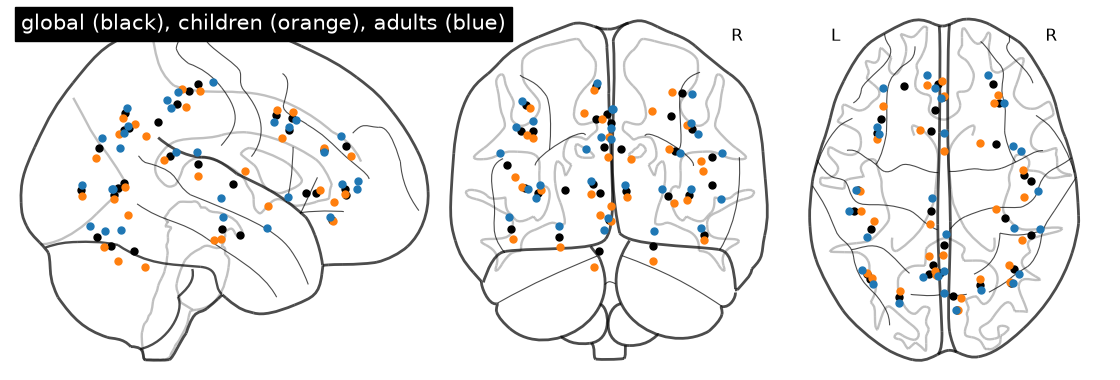

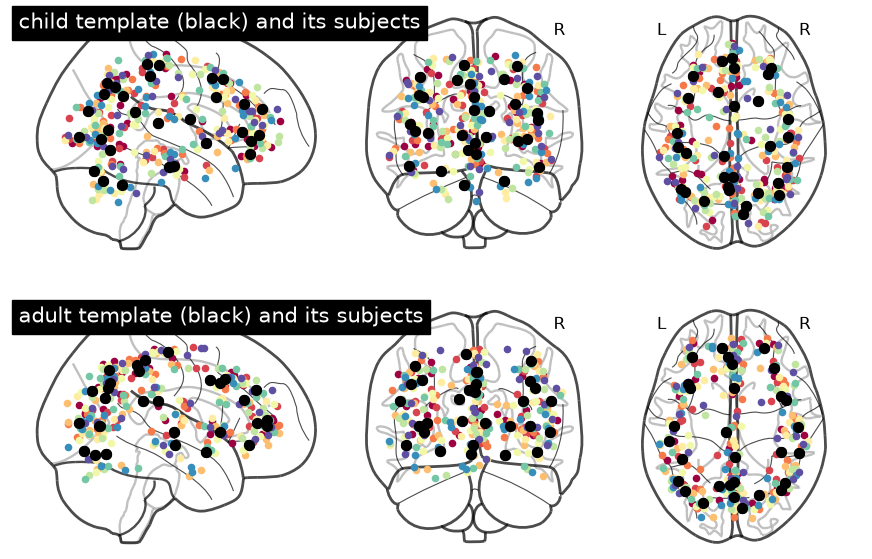

In [13]:
plotting = htfa.require("nilearn.plotting")
colors = {"child": "tab:orange", "adult": "tab:blue"}
fig = plt.figure(figsize=(11, 3.6))
disp = plotting.plot_connectome(
    np.zeros((30, 30)),
    res.display_nodes()[0],
    node_color="black",
    node_size=25,
    figure=fig,
    title="global (black), children (orange), adults (blue)",
    colorbar=False,
)
for g, col in colors.items():
    disp.add_markers(res.display_nodes(group=g)[0], marker_color=col, marker_size=25)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, g in zip(axes, ("child", "adult"), strict=True):
    res.plot_nodes(group=g, ax=ax, title=f"{g} template (black) and its subjects")
plt.show()

In [14]:
child, adult = res.group_centers["child"], res.group_centers["adult"]
dist = np.linalg.norm(child - adult, axis=1)
sd = {
    g: np.sqrt(np.trace(model.group_centers_cov_[i], axis1=1, axis2=2) / 3)
    for i, g in enumerate(model.group_keys_)
}
ratio = res.group_widths["child"] / res.group_widths["adult"]
print(
    "child-adult template distance (mm): median "
    f"{np.median(dist):.1f}, max {dist.max():.1f}"
)
print(
    "posterior SD per coordinate (mm), median over factors:",
    {g: round(float(np.median(v)), 1) for g, v in sd.items()},
)
print(
    "width ratio child / adult: median "
    f"{np.median(ratio):.2f}, range {ratio.min():.2f} to {ratio.max():.2f}"
)

child-adult template distance (mm): median 16.3, max 49.2
posterior SD per coordinate (mm), median over factors: {'child': 3.5, 'adult': 3.5}
width ratio child / adult: median 1.24, range 0.66 to 2.06


The posterior SD comes from the fit's subject-level prior covariance and the tree (each group template is informed by its ten subjects and by the global template); it describes the uncertainty of a template given the subjects' estimates under that prior, not a sampling error over people. The permutation test compares the observed age-group statistics with label-shuffled refits, conditional on the exchangeability assumptions described above; it does not identify the cause of an age-group difference.

## 6. Do children and adults differ?

`res.group_permutation_test(n_permutations=100, random_state=0)` refits the model 100 times with the 20 age labels shuffled. This requires many refits, so by default (`RECOMPUTE_NULL = False (unless REFIT is True)`) the saved result is downloaded instead; it corresponds to the saved fit above and records that fit's SHA-256.

In [15]:
RECOMPUTE_NULL = REFIT
if REFIT and not RECOMPUTE_NULL:
    raise ValueError("A new fit requires its own recomputed permutation test")
NULL_NAME = "development_fmri_children_adults_null_100"
if RECOMPUTE_NULL:
    test = res.group_permutation_test(n_permutations=100, random_state=0, verbose=True)
else:
    saved = htfa.datasets.fetch_tutorial_fit(NULL_NAME, cache_dir=ASSET_CACHE)
    if not REFIT:
        assert str(saved["fit_sha256"]) == htfa.datasets.TUTORIAL_FITS[NAME][1]
    test = GroupTest.from_arrays(saved)
    assert test.reference_centers.shape == (model.K, Rs[0].shape[1])
    assert np.isfinite(test.reference_centers).all()
    assert np.array_equal(np.sort(test.reference_indices), np.arange(model.K))
    print(
        f"saved null: htfa.datasets.fetch_tutorial_fit({NULL_NAME!r}), SHA-256 checked"
    )
print(f"{len(test.center_null)} permutations")
if RECOMPUTE_NULL:
    print(f"permutation time: {test.seconds / 60:.0f} min")
for stat in ("center", "width", "connectivity"):
    p, q = test.pvalues(stat), test.pvalues(stat, fwe=True)
    print(
        f"{stat:>12}: {(p <= 0.05).sum():2d} of 30 factors with p <= 0.05 "
        f"(about 1.5 expected by chance), {(q <= 0.05).sum():2d} family-wise; "
        f"smallest p {p.min():.3f}"
    )

saved null: htfa.datasets.fetch_tutorial_fit('development_fmri_children_adults_null_100'), SHA-256 checked
100 permutations
      center:  1 of 30 factors with p <= 0.05 (about 1.5 expected by chance),  0 family-wise; smallest p 0.020
       width:  2 of 30 factors with p <= 0.05 (about 1.5 expected by chance),  0 family-wise; smallest p 0.010
connectivity:  2 of 30 factors with p <= 0.05 (about 1.5 expected by chance),  0 family-wise; smallest p 0.030


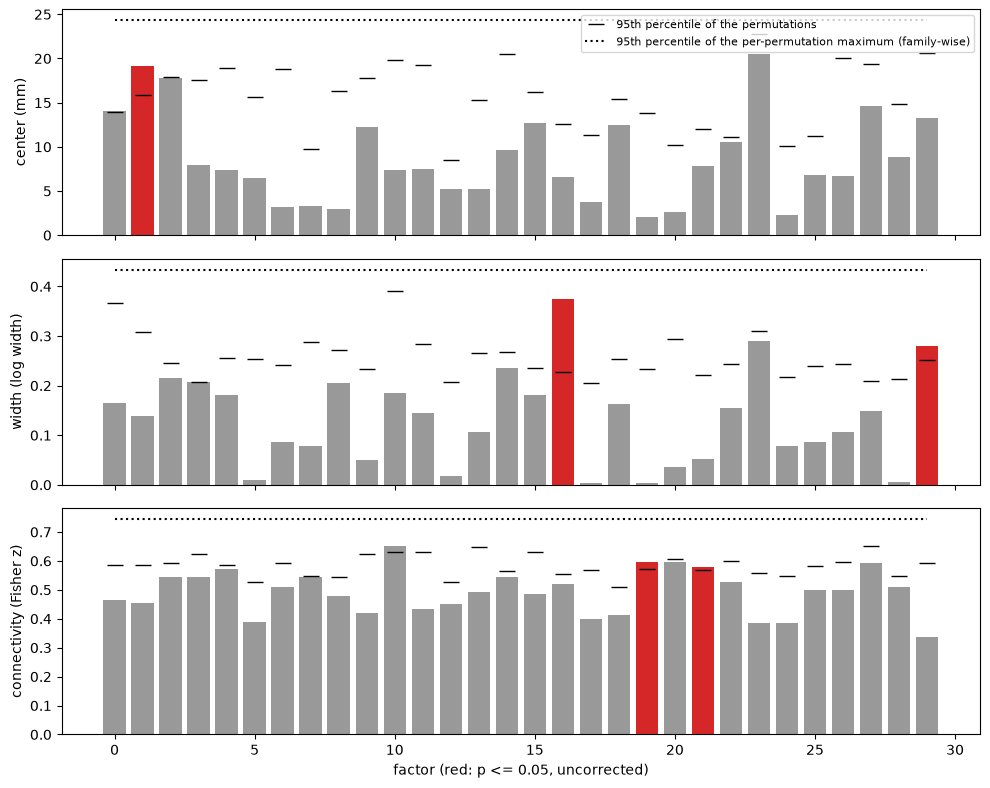

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, stat, unit in zip(
    axes,
    ("center", "width", "connectivity"),
    ("mm", "log width", "Fisher z"),
    strict=True,
):
    obs, null = getattr(test, stat), getattr(test, f"{stat}_null")
    order = np.arange(30)
    ax.bar(order, obs, color=np.where(test.pvalues(stat) <= 0.05, "tab:red", "0.6"))
    ax.plot(
        order,
        np.percentile(null, 95, axis=0),
        "k_",
        ms=12,
        label="95th percentile of the permutations",
    )
    ax.plot(
        order,
        np.full(30, np.percentile(null.max(axis=1), 95)),
        "k:",
        label="95th percentile of the per-permutation maximum (family-wise)",
    )
    ax.set_ylabel(f"{stat} ({unit})")
axes[0].legend(fontsize=8, loc="upper right")
axes[-1].set_xlabel("factor (red: p <= 0.05, uncorrected)")
plt.tight_layout()
plt.show()

The factors whose center differs at the family-wise level, drawn as segments from the child template (orange) to the adult template (blue):

In [17]:
sig = np.flatnonzero(test.pvalues("center", fwe=True) <= 0.05)
print("factors:", sig.tolist())
for k in sig:
    print(
        f"  factor {k}: child {np.round(child[k], 1)}, adult {np.round(adult[k], 1)}, "
        f"{dist[k]:.1f} mm apart, p = {test.pvalues('center')[k]:.3f}, "
        f"family-wise {test.pvalues('center', fwe=True)[k]:.3f}"
    )
if len(sig):
    pairs = np.vstack([child[sig], adult[sig]])
    n = len(sig)
    adj = np.zeros((2 * n, 2 * n))
    adj[np.arange(n), n + np.arange(n)] = adj[n + np.arange(n), np.arange(n)] = 1
    fig = plt.figure(figsize=(11, 3.6))
    plotting.plot_connectome(
        adj,
        pairs,
        node_color=["tab:orange"] * n + ["tab:blue"] * n,
        node_size=30,
        edge_kwargs={"color": "k"},
        figure=fig,
        title="center differences (family-wise p <= 0.05)",
    )
    plt.show()

factors: []


## 7. Connectivity by group

The permutation connectivity statistic above compares each factor's row of the groups' mean **within-subject static connectivity**. The figures below show a different quantity: **inter-subject functional correlation (ISFC)**, which compares aligned factor time courses across participants watching the same movie. The child and adult ISFC matrices use the same factor order and a common symmetric color scale; their difference has its own explicitly labelled scale.

This is a descriptive ISFC comparison. The preceding permutation p-values do **not** test the plotted ISFC difference. `res.plot_network(group=...)` and `res.animate_network(group=...)` can display a group network in 3D (with the `brain3d` extra), but the choice of display does not supply an inferential test.

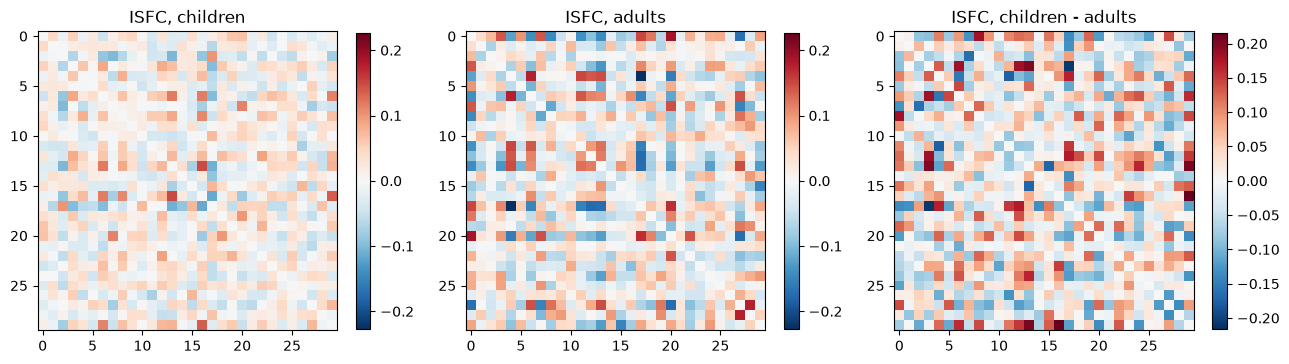

connectivity p <= 0.05 for factors [19, 21] ; family-wise: []
notebook run time: 20 s


In [18]:
isfc = {
    g: htfa.isfc([res.weights[s] for s in res.group_subjects(g)])
    for g in ("child", "adult")
}
off_diagonal = ~np.eye(model.K, dtype=bool)
shared_limit = max(np.abs(m[off_diagonal]).max() for m in isfc.values())
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (title, m) in zip(
    axes,
    [
        ("children", isfc["child"]),
        ("adults", isfc["adult"]),
        ("children - adults", isfc["child"] - isfc["adult"]),
    ],
    strict=True,
):
    m = m.copy()
    np.fill_diagonal(m, 0)
    lim = np.abs(m).max() if title == "children - adults" else shared_limit
    im = ax.imshow(m, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"ISFC, {title}")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()
p = test.pvalues("connectivity")
print(
    "connectivity p <= 0.05 for factors",
    np.flatnonzero(p <= 0.05).tolist(),
    "; family-wise:",
    np.flatnonzero(test.pvalues("connectivity", fwe=True) <= 0.05).tolist(),
)
print(f"notebook run time: {time.perf_counter() - T_START:.0f} s")

**Interpreting the table.** The uncorrected column describes each reference factor separately. When inspecting all 30 factors, use the family-wise values for the chosen statistic. An uncorrected result alone does not establish a group difference after selection across factors. With 100 permutations, p-values have resolution 1/101. Failure to reject a difference is not evidence that the groups are equivalent.

**Caveats.** Ten subjects per group is a small sample. Children of this age move more and have smaller heads, and the data are in a common (MNI) space after registration, so template differences can reflect registration and motion as well as functional organization; the test assesses group differences, not their cause. The p-values are per factor; use the family-wise ones when looking for any difference among the 30 factors.